In [1]:
import pandas as pd

In [32]:
df = pd.read_csv("tested.csv")
df.head(2)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S


In [3]:
print("Total rows and columns: ", df.shape)

Total rows and columns:  (418, 12)


In [4]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Survived     418 non-null    int64  
 2   Pclass       418 non-null    int64  
 3   Name         418 non-null    str    
 4   Sex          418 non-null    str    
 5   Age          332 non-null    float64
 6   SibSp        418 non-null    int64  
 7   Parch        418 non-null    int64  
 8   Ticket       418 non-null    str    
 9   Fare         417 non-null    float64
 10  Cabin        91 non-null     str    
 11  Embarked     418 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 56.1 KB


In [6]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,418.000000,418.000000,418.000000,332.000000,418.000000,418.000000,417.000000
mean,1100.500000,0.363636,2.265550,30.272590,0.447368,0.392344,35.627188
std,120.810458,0.481622,0.841838,14.181209,0.896760,0.981429,55.907576
min,892.000000,0.000000,1.000000,0.170000,0.000000,0.000000,0.000000
25%,996.250000,0.000000,1.000000,21.000000,0.000000,0.000000,7.895800
50%,1100.500000,0.000000,3.000000,27.000000,0.000000,0.000000,14.454200
75%,1204.750000,1.000000,3.000000,39.000000,1.000000,0.000000,31.500000
max,1309.000000,1.000000,3.000000,76.000000,8.000000,9.000000,512.329200


In [7]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64

In [8]:
df['Sex'].value_counts()

Sex
male      266
female    152
Name: count, dtype: int64

In [9]:
df['Pclass'].value_counts()

Pclass
3    218
1    107
2     93
Name: count, dtype: int64

In [10]:
df['Survived'].value_counts()

Survived
0    266
1    152
Name: count, dtype: int64

In [11]:
df['Age'].mean()

np.float64(30.272590361445783)

In [12]:
df['Fare'].max()

np.float64(512.3292)

In [33]:
female_passengers = df[df['Sex'] == 'female']

print(female_passengers.head(5))

    PassengerId  Survived  Pclass  \
1           893         1       3   
4           896         1       3   
6           898         1       3   
8           900         1       3   
12          904         1       1   

                                             Name     Sex   Age  SibSp  Parch  \
1                Wilkes, Mrs. James (Ellen Needs)  female  47.0      1      0   
4    Hirvonen, Mrs. Alexander (Helga E Lindqvist)  female  22.0      1      1   
6                            Connolly, Miss. Kate  female  30.0      0      0   
8       Abrahim, Mrs. Joseph (Sophie Halaut Easu)  female  18.0      0      0   
12  Snyder, Mrs. John Pillsbury (Nelle Stevenson)  female  23.0      1      0   

     Ticket     Fare Cabin Embarked  
1    363272   7.0000   NaN        S  
4   3101298  12.2875   NaN        S  
6    330972   7.6292   NaN        Q  
8      2657   7.2292   NaN        C  
12    21228  82.2667   B45        S  


In [14]:
print("Total female passengers: ", len(female_passengers))

Total female passengers:  152


In [36]:
first_class_females = df[
    (df['Sex'] == 'female') & (df['Pclass'] == 1)
]

print(first_class_females.head(5))

    PassengerId  Survived  Pclass  \
12          904         1       1   
14          906         1       1   
22          914         1       1   
24          916         1       1   
26          918         1       1   

                                                 Name     Sex   Age  SibSp  \
12      Snyder, Mrs. John Pillsbury (Nelle Stevenson)  female  23.0      1   
14  Chaffee, Mrs. Herbert Fuller (Carrie Constance...  female  47.0      1   
22               Flegenheim, Mrs. Alfred (Antoinette)  female   NaN      0   
24    Ryerson, Mrs. Arthur Larned (Emily Maria Borie)  female  48.0      1   
26                       Ostby, Miss. Helene Ragnhild  female  22.0      0   

    Parch       Ticket      Fare            Cabin Embarked  
12      0        21228   82.2667              B45        S  
14      0  W.E.P. 5734   61.1750              E31        S  
22      0     PC 17598   31.6833              NaN        S  
24      3     PC 17608  262.3750  B57 B59 B63 B66        C  
26 

In [37]:
df.head(2)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S


In [17]:
def check_passenger_class(Pclass):
    cls = df['Pclass'] == Pclass
    return df[cls].shape[0]

check_passenger_class(1)

107

In [18]:
df["PassengerId"].value_counts()

PassengerId
892     1
893     1
894     1
895     1
896     1
       ..
1305    1
1306    1
1307    1
1308    1
1309    1
Name: count, Length: 418, dtype: int64

In [19]:
df["Pclass"].value_counts()

Pclass
3    218
1    107
2     93
Name: count, dtype: int64

In [20]:
# The Pandas Plot
import matplotlib.pyplot as plt

<Axes: >

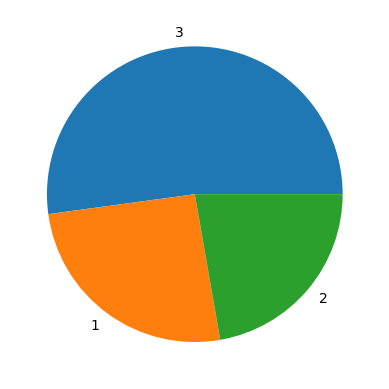

In [21]:
df['Pclass'].value_counts().plot(kind='pie')

<Axes: ylabel='Frequency'>

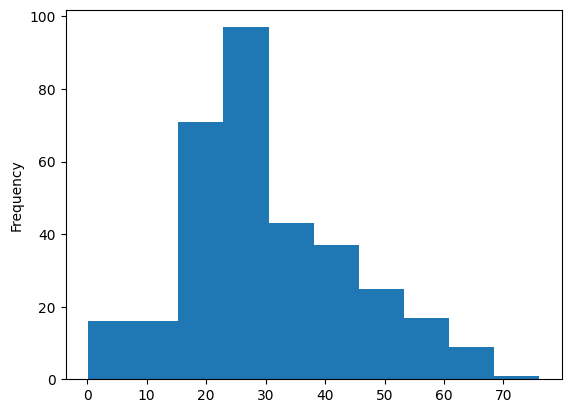

In [22]:
df['Age'].plot(kind='hist')

In [23]:
company = pd.read_csv('Fortune_500_Clean.csv')
company.head(3)

,Rank,Company Name,Number of Employees,Previous Rank,Revenues,Revenue Change,Profits,Profit Change,Assets,Market Value
0,1,Walmart,"23,00,000",1.0,"$4,85,873",0.8%,"$13,643.0",-7.2%,"$1,98,825","$2,18,619"
1,2,Berkshire Hathaway,"3,67,700",4.0,"$2,23,604",6.1%,"$24,074.0",0.0%,"$6,20,854","$4,11,035"
2,3,Apple,"1,16,000",3.0,"$2,15,639",-7.7%,"$45,687.0",-14.4%,"$3,21,686","$7,53,718"


In [24]:
sectors = company.groupby('Company Name')

In [25]:
sectors

In [26]:
len(company)

500

In [27]:
len(sectors)

497

In [28]:
sectors.size().sort_values(ascending=False)

Company Name
Avnet                  2
Alcoa                  2
Regions Financial      2
Whirlpool              1
W.R. Berkley           1
                      ..
Activision Blizzard    1
Adobe Systems          1
Advance Auto Parts     1
Aetna                  1
Weyerhaeuser           1
Length: 497, dtype: int64

In [39]:
sectors.first()

,Rank,Number of Employees,Previous Rank,Revenues,Revenue Change,Profits,Profit Change,Assets,Market Value
Company Name,,,,,,,,,
3M,94,"91,584",93.0,"$30,109",-0.5%,"$5,050.0",4.5%,"$32,906","$1,14,338"
A-Mark Precious Metals,395,"83,000",426.0,"$6,784",11.8%,$9.3,31.5%,$437,$120
ABM Industries,500,"1,10,000",485.0,"$5,145",-2.8%,$57.2,-25.0%,"$2,281","$2,428"
ADP,240,"57,000",248.0,"$11,668",1.7%,"$1,492.5",2.8%,"$43,670","$45,963"
AECOM,161,"87,000",156.0,"$17,411",-3.2%,$96.1,-,"$13,727","$5,528"
...,...,...,...,...,...,...,...,...,...
Yum China Holdings,399,"4,20,000",NaN,"$6,752",-,$502.0,-,"$3,727","$10,453"
Zimmer Biomet Holdings,352,"18,500",431.0,"$7,684",28.1%,$305.9,108.1%,"$26,684","$24,571"
eBay,310,"12,600",300.0,"$8,979",-5.4%,"$7,266.0",321.2%,"$23,847","$36,232"


In [30]:
sectors.groups

# company.iloc[23, :]

{'3M': [93], 'A-Mark Precious Metals': [394], 'ABM Industries': [499], 'ADP': [239], 'AECOM': [160], 'AES': [193], 'AGCO': [369], 'AIG': [54], 'AK Steel Holding': [440], 'AT&T': [8], 'AbbVie': [110], 'Abbott Laboratories': [134], 'Activision Blizzard': [405], 'Adobe Systems': [442], 'Advance Auto Parts': [291], 'Aetna': [42], 'Aflac': [125], 'Air Products & Chemicals': [293], 'Airgas': [488], 'Alaska Air Group': [437], 'Albertsons Cos.': [48], 'Alcoa': [227, 299], 'Alleghany': [427], 'Alliance Data Systems': [377], 'Allstate': [83], 'Ally Financial': [285], 'Alphabet': [26], 'Altria Group': [147], 'AmTrust Financial Services': [474], 'Amazon.com': [11], 'Ameren': [430], 'American Airlines Group': [66], 'American Electric Power': [166], 'American Express': [85], 'American Family Insurance Group': [314], 'American Financial Group': [410], 'American Tower': [448], 'Ameriprise Financial': [238], 'AmerisourceBergen': [10], 'Amgen': [122], 'Amphenol': [423], 'Anadarko Petroleum': [343], 'Ani

In [ ]:
sectors.get_group('Company Name')

In [ ]:
sectors.sum()

In [ ]:
sectors.mean()

In [ ]:
sectors['Revenues'].mean().sort_values(ascending=False)

In [ ]:
df[df('Sex')['Survived'].mean()]